# Практика 1.4. Случайный лес

**Задача:** многоклассовая классификация возрастной группы морского моллюска **абалона** по физическим измерениям. Классически возраст определяют, распиливая раковину и считая кольца под микроскопом, — долго и трудоёмко. Модель позволяет оценить возраст по простым измерениям.

**Датасет:** [Abalone (UCI)](https://archive.ics.uci.edu/dataset/1/abalone) — 4 177 особей, 8 признаков:

| Признак | Описание |
|---|---|
| `sex` | пол: M, F, I (infant — неполовозрелая особь) — **текстовый** |
| `length`, `diameter`, `height` | размеры раковины, мм/200 |
| `whole_weight`, `shucked_weight`, `viscera_weight`, `shell_weight` | масса целиком / мяса / внутренностей / раковины, г/200 |
| `rings` | число колец (возраст ≈ rings + 1.5 года) |

**Целевая переменная** — возрастная группа: `young` (≤ 8 колец), `adult` (9–11), `old` (≥ 12).

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p1_random_forest"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"
COLUMNS = ["sex", "length", "diameter", "height", "whole_weight",
           "shucked_weight", "viscera_weight", "shell_weight", "rings"]
NUM_COLS = COLUMNS[1:-1]
CAT_COLS = ["sex"]
TARGET = "age_group"
CLASS_ORDER = ["young", "adult", "old"]
PARAM_GRID = {
    "n_estimators": [200, 400],
    "max_depth": [None, 8, 14],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 3, 5],
}


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


def classification_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }

2026/11/10 13:30:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 13:30:04 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 13:30:14 INFO mlflow.tracking.fluent: Experiment with name 'p1_random_forest' does not exist. Creating a new experiment.


**Трекинг экспериментов.** Все запуски логируются в MLflow (база `mlflow.db` в корне репозитория).
Посмотреть результаты: из корня репозитория выполнить `mlflow ui --backend-store-uri sqlite:///mlflow.db` и открыть http://127.0.0.1:5000.

## 2. Загрузка данных

In [4]:
raw = pd.read_csv(download(DATA_URL, "abalone.data"), header=None, names=COLUMNS)
df = raw.copy()
print(f"Размер: {df.shape}")
df.head()

Размер: (4177, 9)


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [5]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sex             4177 non-null   object 
 1   length          4177 non-null   float64
 2   diameter        4177 non-null   float64
 3   height          4177 non-null   float64
 4   whole_weight    4177 non-null   float64
 5   shucked_weight  4177 non-null   float64
 6   viscera_weight  4177 non-null   float64
 7   shell_weight    4177 non-null   float64
 8   rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


,count,mean,std,min,25%,50%,75%,max
length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
whole_weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
shucked_weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
viscera_weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
shell_weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


## 3. Качество данных
### 3.1. Типы, пропуски, допустимые категории

In [6]:
df["sex"] = df["sex"].str.strip().str.upper()
df[NUM_COLS + ["rings"]] = df[NUM_COLS + ["rings"]].apply(pd.to_numeric, errors="coerce")
print("Значения sex:", df["sex"].value_counts(dropna=False).to_dict())
quality_report(df)

Значения sex: {'M': 1528, 'I': 1342, 'F': 1307}


,dtype,missing,missing_%,unique
sex,object,0,0.0,3
length,float64,0,0.0,134
diameter,float64,0,0.0,111
height,float64,0,0.0,51
whole_weight,float64,0,0.0,2429
shucked_weight,float64,0,0.0,1515
viscera_weight,float64,0,0.0,880
shell_weight,float64,0,0.0,926
rings,int64,0,0.0,28


**Стратегия:** строки с неизвестным полом (не M/F/I) или без числа колец удаляем — восстановить их нельзя; пропуски в измерениях заполняются медианой внутри Pipeline.

In [7]:
before = len(df)
df = df[df["sex"].isin(["M", "F", "I"]) & df["rings"].notna()].reset_index(drop=True)
print(f"Удалено строк: {before - len(df)}")

Удалено строк: 0


### 3.2. Дубликаты

In [8]:
n_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {n_duplicates}")
df = df.drop_duplicates().reset_index(drop=True)

Полных дубликатов: 0


### 3.3. Аномалии
В этом датасете есть настоящие «битые» записи, которые видно из физического смысла:
- **нулевая высота** раковины — невозможна;
- **части тяжелее целого**: масса мяса, внутренностей или раковины больше массы всей особи;
- **экстремальные выбросы** по высоте (IQR, k = 3) — опечатки в измерениях.

In [9]:
checks = pd.DataFrame({
    "нулевые/отриц. размеры": (df[["length", "diameter", "height"]] <= 0).any(axis=1),
    "мясо > целого": df["shucked_weight"] > df["whole_weight"],
    "внутренности > целого": df["viscera_weight"] > df["whole_weight"],
    "раковина > целого": df["shell_weight"] > df["whole_weight"],
    "экстремальная высота": iqr_outlier_mask(df[["height"]], k=3)["height"],
})
print(checks.sum().to_string())
anomalies = checks.any(axis=1)
print(f"\nВсего аномальных строк: {anomalies.sum()}")

нулевые/отриц. размеры    2
мясо > целого             4
внутренности > целого     0
раковина > целого         1
экстремальная высота      2

Всего аномальных строк: 8


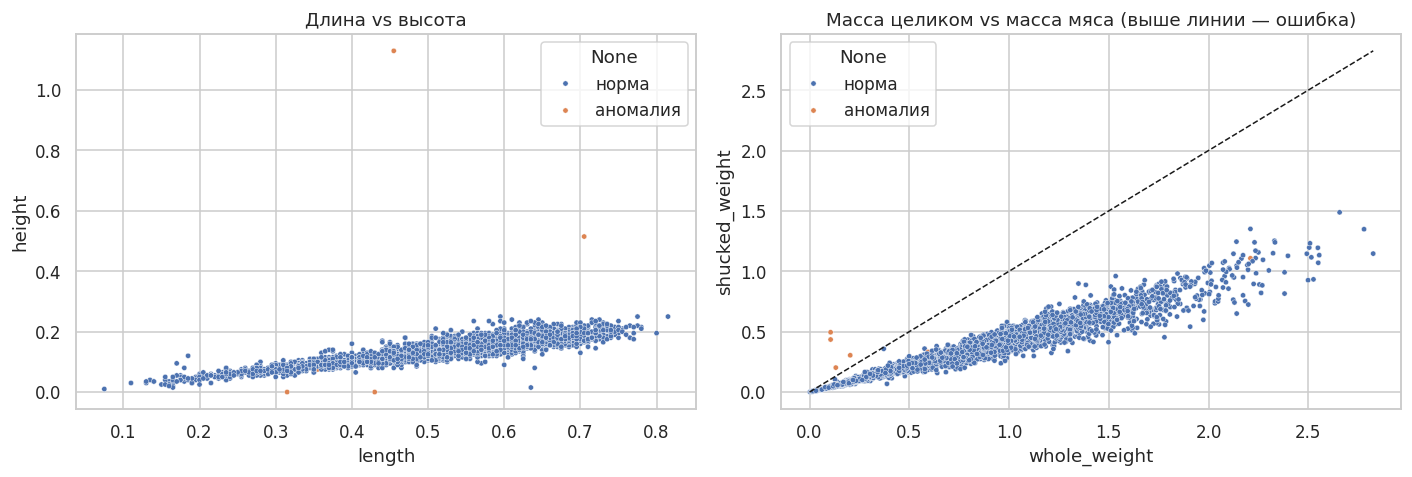

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="length", y="height", hue=anomalies.map({True: "аномалия", False: "норма"}), ax=axes[0], s=12)
axes[0].set_title("Длина vs высота")
sns.scatterplot(data=df, x="whole_weight", y="shucked_weight", hue=anomalies.map({True: "аномалия", False: "норма"}), ax=axes[1], s=12)
axes[1].plot([0, df["whole_weight"].max()], [0, df["whole_weight"].max()], "k--", lw=1)
axes[1].set_title("Масса целиком vs масса мяса (выше линии — ошибка)")
plt.tight_layout()
plt.show()

In [11]:
df = df.loc[~anomalies].reset_index(drop=True)
print(f"Размер после очистки: {df.shape}")

Размер после очистки: (4169, 9)


### 3.4. Целевая переменная

In [12]:
df[TARGET] = pd.cut(df["rings"], bins=[0, 8, 11, np.inf], labels=CLASS_ORDER).astype(str)
df[TARGET].value_counts().reindex(CLASS_ORDER)

,count
age_group,
young,1400
adult,1809
old,960


## 4. Разведочный анализ (EDA)
### 4.1. Распределения

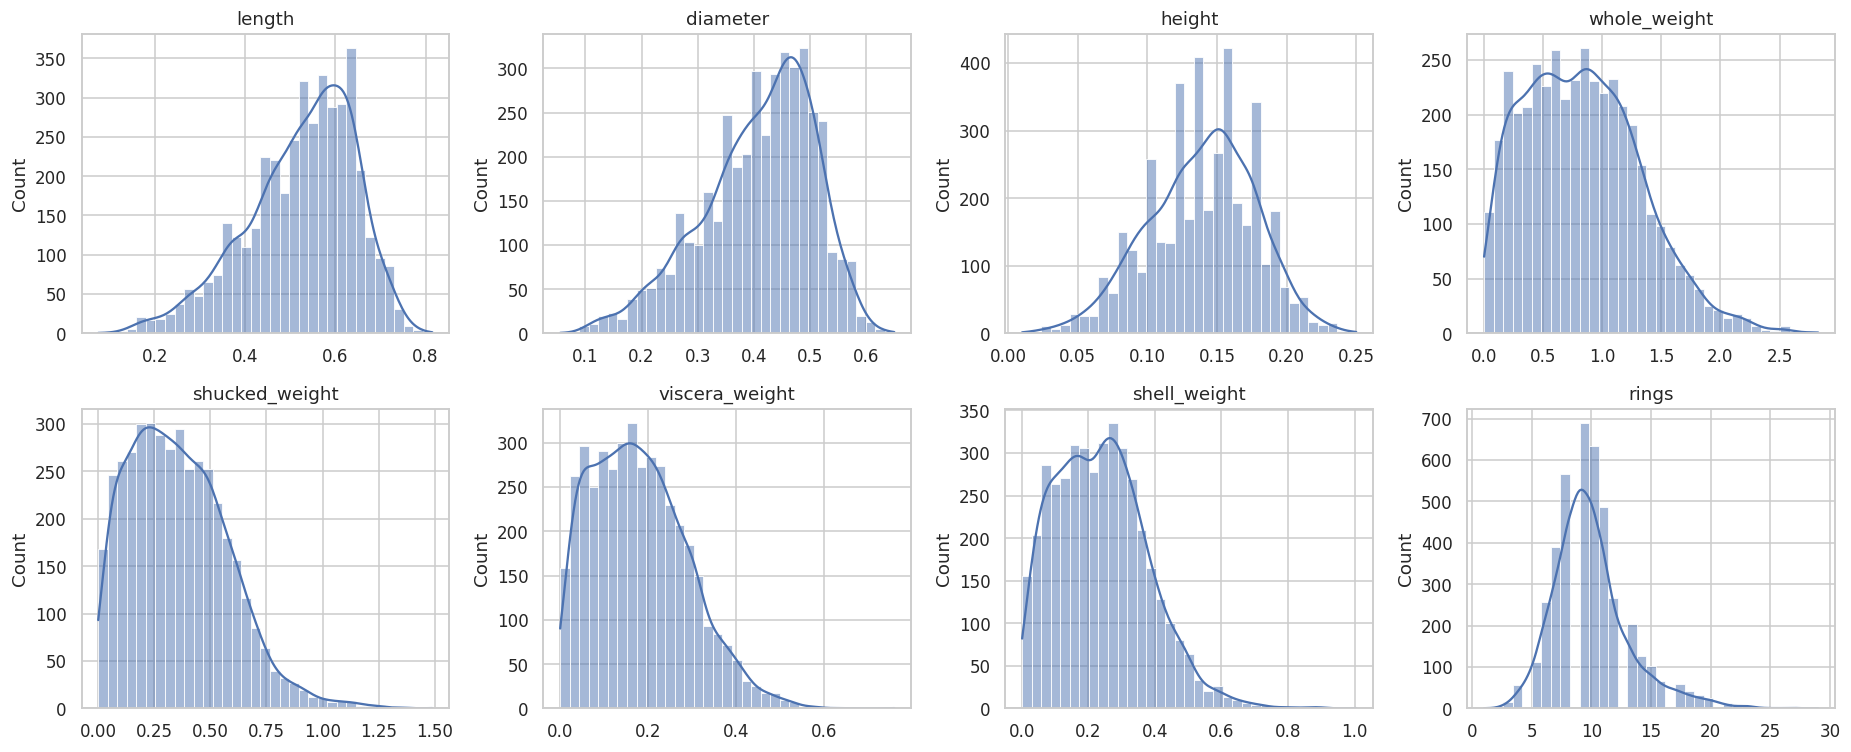

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), NUM_COLS + ["rings"]):
    sns.histplot(df[col], kde=True, ax=ax, bins=35)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

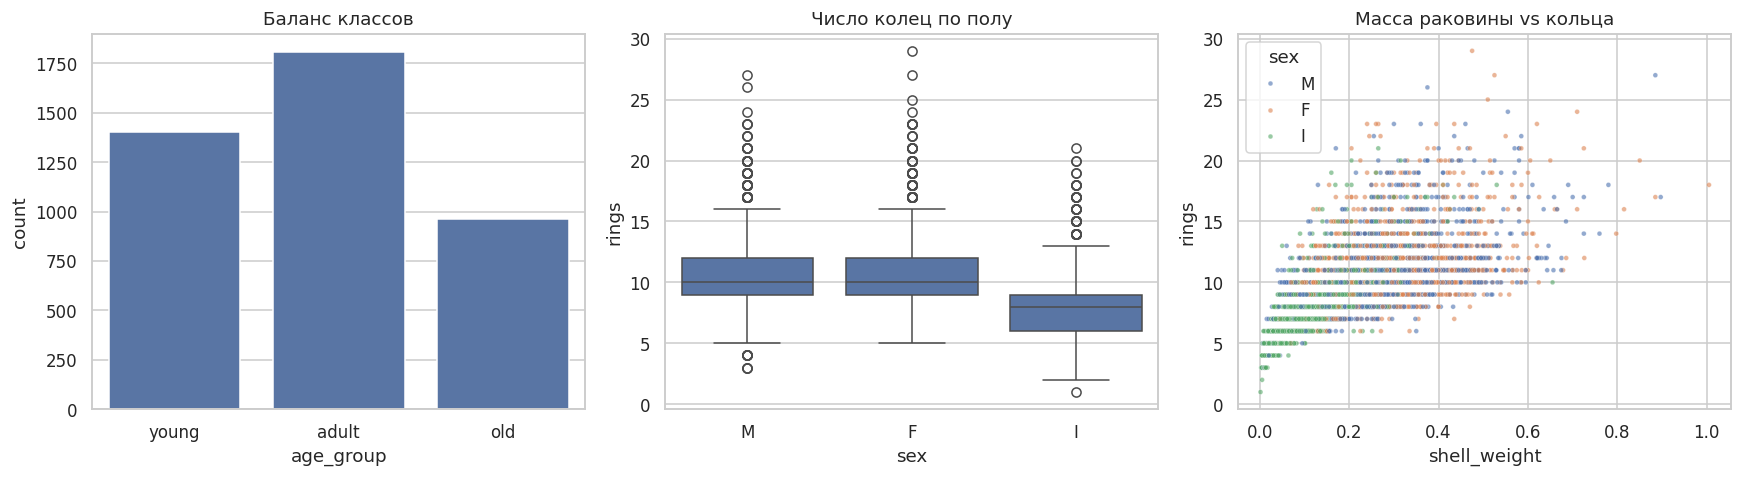

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.countplot(x=df[TARGET], order=CLASS_ORDER, ax=axes[0])
axes[0].set_title("Баланс классов")
sns.boxplot(data=df, x="sex", y="rings", ax=axes[1])
axes[1].set_title("Число колец по полу")
sns.scatterplot(data=df, x="shell_weight", y="rings", hue="sex", s=10, alpha=0.6, ax=axes[2])
axes[2].set_title("Масса раковины vs кольца")
plt.tight_layout()
plt.show()

### 4.2. Матрица корреляции
Пол временно кодируем индикаторами (One-Hot), чтобы включить его в матрицу.

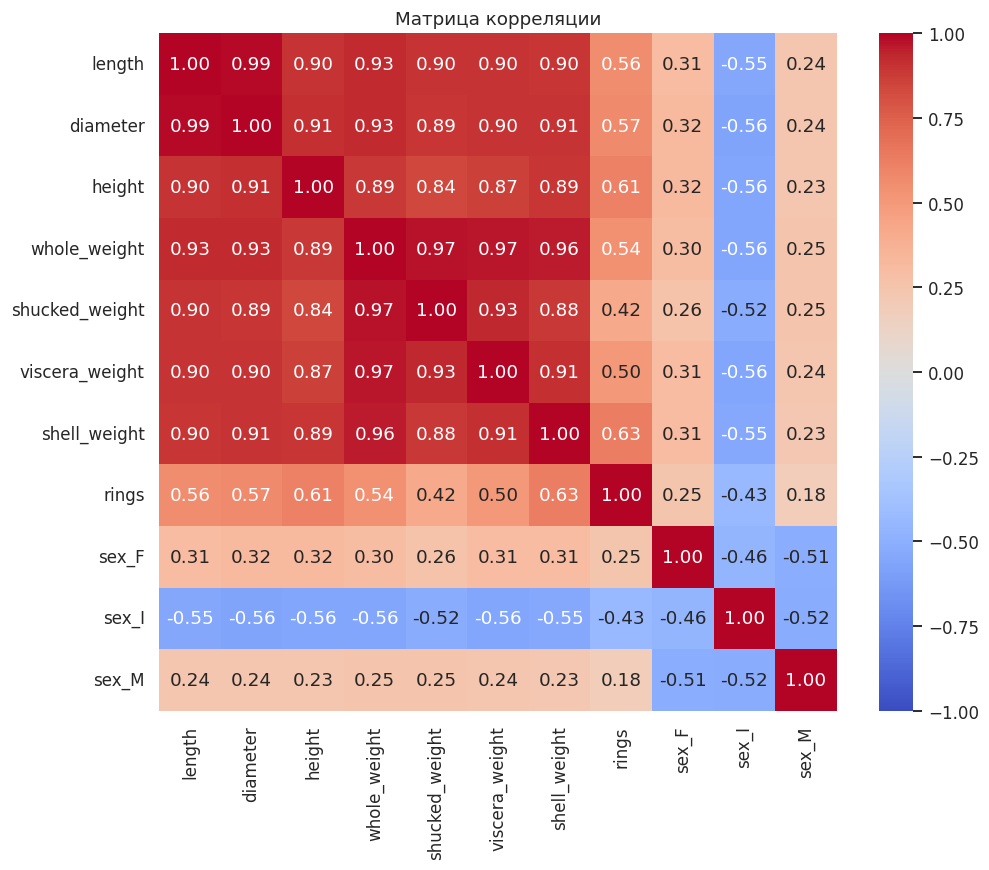

In [15]:
corr_frame = pd.concat([df[NUM_COLS + ["rings"]], pd.get_dummies(df["sex"], prefix="sex", dtype=int)], axis=1)
plt.figure(figsize=(10, 8))
sns.heatmap(corr_frame.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Матрица корреляции")
plt.show()

**Наблюдения EDA:**
- размеры и массы почти линейно связаны между собой (корреляция 0,84–0,99, длина и диаметр — 0,99) — сильная мультиколлинеарность. Для случайного леса это не проблема, но важность признаков «размазывается» между похожими признаками;
- с числом колец сильнее всего связаны масса раковины (0,63) и высота (0,61), слабее всего — масса мяса (0,42);
- неполовозрелые особи (`I`) заметно моложе (медиана ≈ 8 колец против ≈ 10 у M и F, корреляция `sex_I` с кольцами −0,43) — признак пола информативен;
- после 0,4–0,5 по массе раковины число колец почти перестаёт расти — возраст старых особей по размерам определяется плохо;
- классы умеренно несбалансированы (young 1 400, adult 1 809, old 960), поэтому кроме accuracy смотрим F1-macro.

## 5. Кодирование и разбиение
Пол кодируем One-Hot, числовые признаки не масштабируем (деревьям это не нужно). Разбиение 60/20/20 со стратификацией.

In [16]:
X = df[NUM_COLS + CAT_COLS]
y = df[TARGET]
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=SEED
)
print(f"train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])


def build_model(estimator):
    return Pipeline([("prep", preprocessor), ("model", estimator)])

train: 2501, val: 834, test: 834


## 6. Подбор гиперпараметров случайного леса
- `n_estimators` — число деревьев (больше — стабильнее, но дольше);
- `max_depth`, `min_samples_leaf` — ограничение сложности каждого дерева;
- `max_features` — сколько признаков рассматривается в каждом разбиении. Именно случайный выбор признаков делает деревья непохожими друг на друга, и их усреднение снижает дисперсию.

Также выводим **OOB-оценку** (out-of-bag): каждое дерево обучается на бутстрэп-выборке, а объекты, не попавшие в неё, служат «встроенной» валидацией.

In [17]:
val_rows = []
for params in ParameterGrid(PARAM_GRID):
    forest = RandomForestClassifier(oob_score=True, n_jobs=-1, random_state=SEED, **params)
    model = build_model(forest).fit(X_train, y_train)
    metrics = classification_metrics(y_val, model.predict(X_val))
    val_rows.append({**params, "oob_accuracy": forest.oob_score_, **metrics})

val_table = pd.DataFrame(val_rows)
best_row = val_table.sort_values("f1_macro", ascending=False).iloc[0]
best_params = {
    "n_estimators": int(best_row["n_estimators"]),
    "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    "max_features": best_row["max_features"],
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
}
print(f"Лучшие параметры: {best_params}")
val_table.sort_values("f1_macro", ascending=False).head(10).round(4)

Лучшие параметры: {'n_estimators': 200, 'max_depth': 14, 'max_features': 'sqrt', 'min_samples_leaf': 3}


,max_depth,max_features,min_samples_leaf,n_estimators,oob_accuracy,accuracy,f1_macro
26,14.0,sqrt,3,200,0.6877,0.6751,0.6642
16,8.0,sqrt,5,200,0.6925,0.6763,0.6637
17,8.0,sqrt,5,400,0.6885,0.6763,0.6633
18,8.0,0.5,1,200,0.6901,0.6739,0.6632
19,8.0,0.5,1,400,0.6861,0.6727,0.6615
28,14.0,sqrt,5,200,0.6849,0.6715,0.6612
27,14.0,sqrt,3,400,0.6869,0.6703,0.6610
21,8.0,0.5,3,400,0.6893,0.6715,0.6610
23,8.0,0.5,5,400,0.6957,0.6715,0.6602
9,NaN,0.5,3,400,0.6821,0.6691,0.6600


In [18]:
with mlflow.start_run(run_name="rf_grid_search"):
    mlflow.log_params({f"best_{k}": v for k, v in best_params.items()})
    mlflow.log_param("grid_size", len(val_table))
    mlflow.log_metrics({f"val_{k}": float(best_row[k]) for k in ["accuracy", "f1_macro", "oob_accuracy"]})

## 7. Финальная оценка на тесте

In [19]:
final_forest = RandomForestClassifier(n_jobs=-1, random_state=SEED, **best_params)
final_model = build_model(final_forest).fit(X_train_full, y_train_full)
test_pred = final_model.predict(X_test)
test_metrics = classification_metrics(y_test, test_pred)
print(classification_report(y_test, test_pred, labels=CLASS_ORDER))
pd.Series(test_metrics).round(4)

              precision    recall  f1-score   support

       young       0.82      0.73      0.77       280
       adult       0.63      0.74      0.68       362
         old       0.63      0.51      0.56       192

    accuracy                           0.68       834
   macro avg       0.69      0.66      0.67       834
weighted avg       0.69      0.68      0.68       834



,0
accuracy,0.6835
f1_macro,0.6697


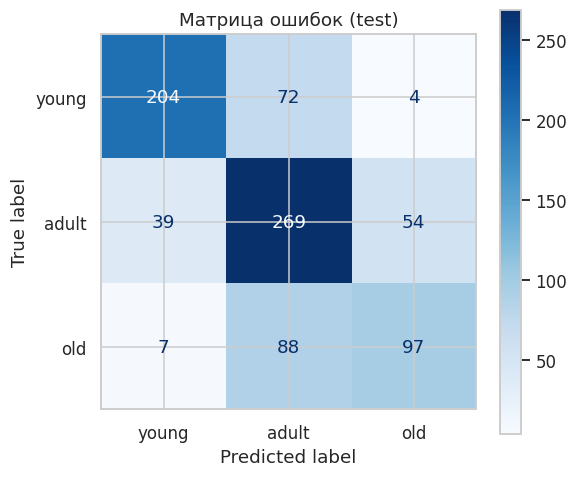

In [20]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=CLASS_ORDER, cmap="Blues", ax=ax)
ax.set_title("Матрица ошибок (test)")
plt.show()

Ошибки сосредоточены между **соседними** группами (young↔adult, adult↔old): границы групп по кольцам условны, а особи на границе физически почти не отличаются. Путаница young↔old встречается редко — модель уловила общую закономерность.

### Важность признаков
Сравниваем два способа:
- **MDI** (mean decrease in impurity) — встроенная важность, считается на train; склонна завышать важность признаков с большим числом уникальных значений;
- **Permutation importance** — насколько падает качество на **тесте**, если случайно перемешать значения признака. Более честная оценка.

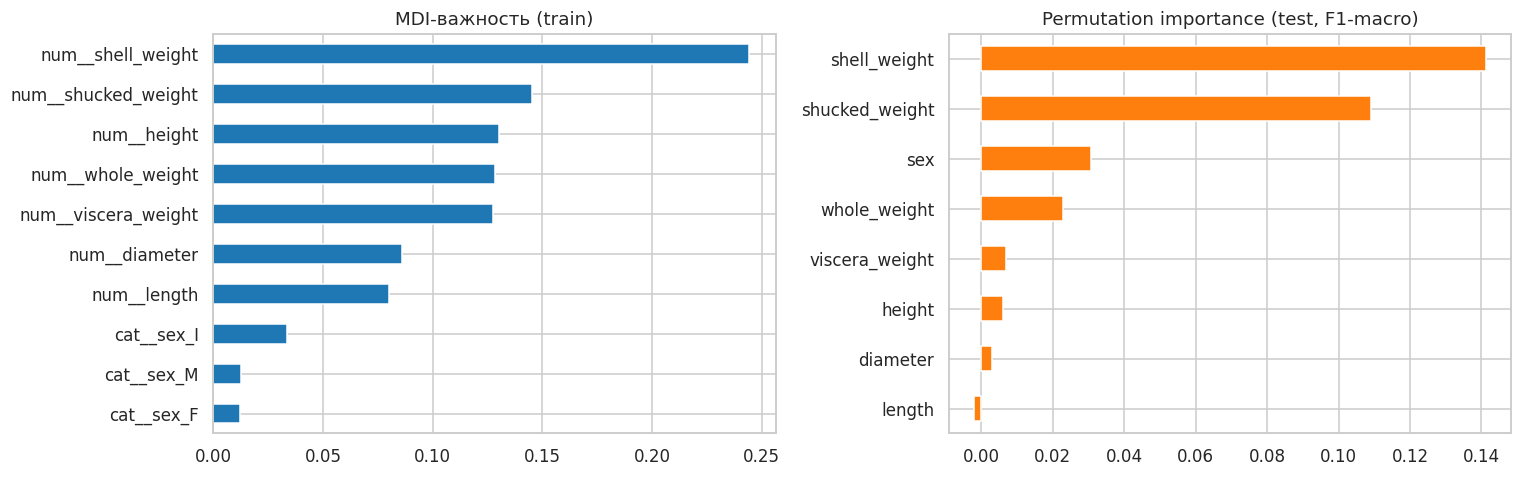

In [21]:
feature_names = final_model.named_steps["prep"].get_feature_names_out()
mdi = pd.Series(final_forest.feature_importances_, index=feature_names)
perm = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=SEED, scoring="f1_macro", n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
mdi.sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("MDI-важность (train)")
perm_importance.sort_values().plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_title("Permutation importance (test, F1-macro)")
plt.tight_layout()
plt.show()

In [22]:
with mlflow.start_run(run_name="rf_final"):
    mlflow.log_params({**best_params, "n_train": len(X_train_full)})
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig, "feature_importance.png")
print("Финальный запуск записан в MLflow")

Финальный запуск записан в MLflow


## 8. Выводы
- **Качество данных.** Пропусков, неизвестных категорий пола и дубликатов в 4 177 записях нет. Найдено и удалено 8 физически невозможных записей: нулевая высота (2), масса мяса больше массы целой особи (4), масса раковины больше целой (1), экстремальная высота (2; часть проверок срабатывает на одних и тех же строках). Осталось 4 169 записей.
- **Кодирование.** Пол закодирован One-Hot, число колец преобразовано в 3 возрастные группы.
- **Подбор параметров.** Лучшая конфигурация на валидации: 200 деревьев, глубина до 14, `max_features = "sqrt"`, минимум 3 объекта в листе (F1-macro 0,664). OOB-оценка (0,688) согласуется с валидационной — встроенная валидация леса подтверждает результат. Десять лучших конфигураций различаются по F1 меньше чем на 0,005 — лес устойчив к выбору гиперпараметров.
- **Итог на тесте (834 особи):** accuracy **0,684**, F1-macro **0,670**. Лучше всего распознаются молодые особи (F1 0,77), хуже всего — старые (F1 0,56).
- **Анализ ошибок.** Ошибки почти всегда между **соседними** группами: young ↔ old перепутаны лишь 11 раз из 834. Чаще всего старые особи принимаются за взрослых (88 из 192): после ~12 колец рост раковины замедляется, и по размерам старую особь трудно отличить от взрослой. Это ограничение данных, а не модели: физические измерения объясняют возраст лишь частично.
- **Важность признаков.** По обоим методам главный признак — **масса раковины**. Permutation importance на тесте ставит на второе место **массу мяса**, хотя её корреляция с кольцами самая низкая (0,42): лес использует её **вместе** с общей массой — с возрастом доля раковины растёт, а доля мяса падает. Длина почти бесполезна, так как дублирует диаметр (корреляция 0,99). Пол важен за счёт отделения неполовозрелых особей.